# 01 · Preprocessing — Chen 2020 NPC (malignant compartment)

Isolate malignant cells, threshold thin samples by a **data-driven multiplicative
gap** (watching the *clean-gap* assumption — this distribution has two cliffs),
integrate patients (Harmony, strength chosen by an **iLISI sweep**), embed, check
for detached islands, and annotate transcriptional subtypes from **data markers +
the study's own malignant meta-programs** (Chen 2020 / 3CA `mp_top`).

**Gate 1** is judged on the regenerated embedding across the integration sweep plus
a per-neighbourhood mixing metric (iLISI) — not a single scalar — and each
sub-region's biology (cell cycle + the three embryonic signatures) is settled
before the GO. Deliverable: `processed.h5ad`, `samples.pdf`.

In [1]:
import os, sys
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
from scipy.stats import pearsonr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata

# dataset folder drops the trailing '-5' attempt suffix
raw_name = name[:-2] if name.endswith('-5') else name
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + raw_name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat, '| raw:', raw_name)

dataset: Chen2020_Head-and-Neck-5 | category: Head-and-Neck | raw: Chen2020_Head-and-Neck


### Load malignant compartment
Chen et al. provide per-cell type calls; we take their `Malignant` cells. The
per-cell table (`Cells.csv`) also carries the study's malignant **meta-program**
label (`mp_top`), EBV status, and cell-cycle phase — used below for annotation.

In [3]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs.celltype == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())

# merge the study's per-cell metadata (meta-program, EBV, cell-cycle phase)
cells = pd.read_csv(os.path.join(pth_in, 'Cells.csv')).set_index('cell_name')
for col in ['mp_top', 'ebv', 'cell_cycle_phase']:
    adata.obs[col] = adata.obs_names.map(cells[col].replace('', np.nan))
print('meta-programs present:', adata.obs['mp_top'].notna().sum(), '/', adata.n_obs)

Loading ../../../../../../data/unzip/CCCA/Data_Chen2020_Head-and-Neck
/home/caleb/miniconda3/envs/scFates/lib/python3.11/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
Done.
full atlas: (71896, 36695)
malignant: (3763, 36695) | samples: 14
meta-programs present: 3674 / 3763


### Sample thresholding — multiplicative gap-finding, with the two-gap caveat
Sort per-sample malignant counts and look for the largest **multiplicative** cliff.
**Caveat (C3, clean-gap assumption):** this distribution has *two* cliffs. The
largest (838→236, 3.55×) merely separates the two dominant tumours from the rest —
cutting there would keep only 2 samples and destroy the batch-integration test. The
**QC-relevant** separatrix is the next cliff, 107→36 (2.97×), which divides 8
adequately-sampled tumours (≥100 cells) from 6 sparse/spillover ones (≤36). We cut
at that gap (its geometric mean), matching the depth-adequacy rationale behind
Puram's ≥100.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
print('sorted per-sample counts:', n.values.tolist())
cliffs = [(i, n.index[i], int(vals[i]), n.index[i+1], int(vals[i+1]), ratios[i])
          for i in range(len(ratios)) if ratios[i] > 2.5]
print('multiplicative cliffs (>2.5x):')
for i,a,va,b,vb,r in cliffs:
    print(f'  {a}({va}) -> {b}({vb})  ratio {r:.2f}')

# choose the QC separatrix: the cliff in the depth-adequate regime (upper count >= 50)
qc = [c for c in cliffs if c[4] < 50 <= c[2]]
gap = qc[0][0] if qc else int(np.argmax(ratios))
thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
print(f'QC separatrix: {n.index[gap]}({int(vals[gap])}) -> {n.index[gap+1]}({int(vals[gap+1])})'
      f' | threshold (geo-mean) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells')

sorted per-sample counts: [1814, 838, 236, 234, 197, 136, 112, 107, 36, 25, 13, 6, 5, 4]
multiplicative cliffs (>2.5x):
  P01(838) -> P12(236)  ratio 3.55
  P03(107) -> P02(36)  ratio 2.97
QC separatrix: P03(107) -> P02(36) | threshold (geo-mean) = 62
kept 8/14 samples -> 3674 cells


### Overdispersed genes + PCA (no scaling)
`scFates.pp.find_overdispersed` selects the over-dispersed feature set (GAM fit; no
`sc.pp.scale` before PCA — matching the reference protocol). The scree plot informs
`n_pcs`: the variance drops steeply through ~6 PCs then carries a long structured
tail — an elbow-cut would under-power the manifold, so we take `n_pcs=20` (≈47%
cumulative variance), the scale used for the 10x reference.

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1290 over-dispersed features (0:00:02) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 1290
cumulative var @ n_pcs=20: 0.474


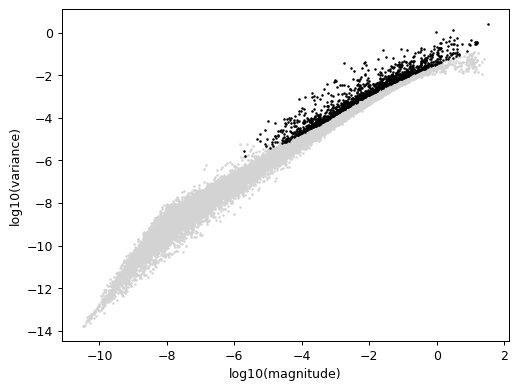

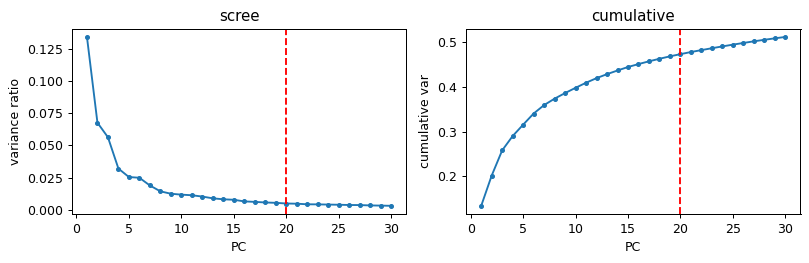

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata, plot=True)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
vr = adata.uns['pca']['variance_ratio']
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].plot(range(1, 31), vr[:30], 'o-', ms=3); ax[0].axvline(20, ls='--', c='r')
ax[0].set(xlabel='PC', ylabel='variance ratio', title='scree')
ax[1].plot(range(1, 31), np.cumsum(vr[:30]), 'o-', ms=3); ax[1].axvline(20, ls='--', c='r')
ax[1].set(xlabel='PC', ylabel='cumulative var', title='cumulative')
fig.tight_layout()
print('cumulative var @ n_pcs=20:', round(float(np.cumsum(vr)[19]), 3))

### Harmony integration strength — iLISI sweep (Gate 1 mixing evidence)
The malignant pool is dominated by two tumours (P11+P01 ≈ 72%), so integration is a
genuine stress test. We sweep Harmony `theta` (0/2/5/10) and score batch mixing with
**iLISI** (local inverse-Simpson over `sample`; 1 = patient-private, higher = more
mixed, max = n_samples). Un-integrated (theta=0) fragments into per-patient islands
(iLISI≈1); integration lifts mixing onto a plateau (iLISI≈2.1–2.2). This plateau —
not the full n_samples — is the expected malignant signature: shared cell-state axes
mix while patient-specific CNV identity persists as a secondary axis. `theta=5` gives
the best mixing and is carried forward.

2026-07-29 16:21:08,539 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-07-29 16:21:11,483 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-07-29 16:21:11,534 - harmonypy - INFO - Iteration 1 of 20
2026-07-29 16:21:12,746 - harmonypy - INFO - Iteration 2 of 20
2026-07-29 16:21:13,900 - harmonypy - INFO - Iteration 3 of 20
2026-07-29 16:21:14,961 - harmonypy - INFO - Iteration 4 of 20
2026-07-29 16:21:15,875 - harmonypy - INFO - Iteration 5 of 20
2026-07-29 16:21:17,033 - harmonypy - INFO - Iteration 6 of 20
2026-07-29 16:21:18,081 - harmonypy - INFO - Iteration 7 of 20
2026-07-29 16:21:18,773 - harmonypy - INFO - Iteration 8 of 20
2026-07-29 16:21:19,562 - harmonypy - INFO - Iteration 9 of 20
2026-07-29 16:21:20,045 - harmonypy - INFO - Iteration 10 of 20
2026-07-29 16:21:21,130 - harmonypy - INFO - Iteration 11 of 20
2026-07-29 16:21:21,869 - harmonypy - INFO - Iteration 12 of 20
2026-07-29 16:21:22,250 - harmonypy - INFO - Iteration 13 of

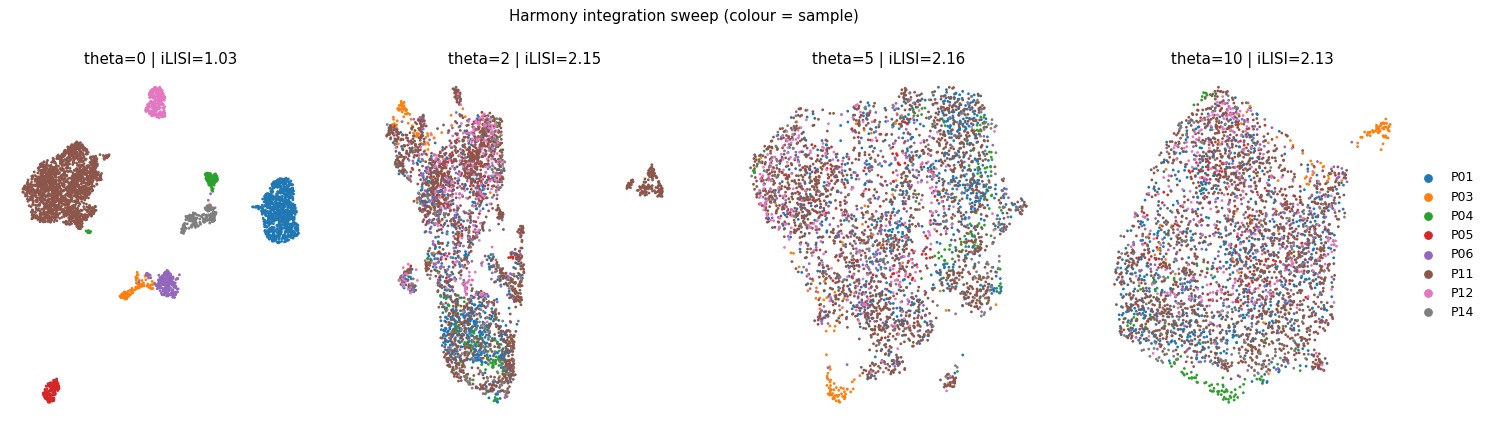

In [6]:
def ilisi(X, labs, n_neighbors=30):
    nn = NearestNeighbors(n_neighbors=n_neighbors).fit(X); _, idx = nn.kneighbors(X)
    K = labs.max()+1; out = np.empty(len(labs))
    for i in range(len(labs)):
        p = np.bincount(labs[idx[i]], minlength=K).astype(float); p /= p.sum()
        out[i] = 1.0/np.sum(p**2)
    return out
labs = adata.obs['sample'].astype('category').cat.codes.values

fig, axes = plt.subplots(1, 4, figsize=(20, 5)); sweep = {}
for j, theta in enumerate([0, 2, 5, 10]):
    ad = adata.copy()
    if theta == 0:
        ad.obsm['X_pca_harmony'] = ad.obsm['X_pca'].copy()
    else:
        sce.pp.harmony_integrate(ad, 'sample', theta=theta, max_iter_harmony=20, random_state=SEED)
    sc.pp.neighbors(ad, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
    sc.tl.umap(ad, spread=1.3, random_state=SEED)
    il = ilisi(ad.obsm['X_pca_harmony'][:, :20], labs); sweep[theta] = il.mean()
    sc.pl.umap(ad, color='sample', size=20, frameon=False, show=False, ax=axes[j],
               legend_loc='right margin' if j == 3 else None,
               title=f'theta={theta} | iLISI={il.mean():.2f}')
fig.suptitle('Harmony integration sweep (colour = sample)', y=1.02)
print('iLISI by theta:', {k: round(v, 2) for k, v in sweep.items()},
      '| n_samples =', adata.obs['sample'].nunique())

In [7]:
# commit theta=5 (best mixing); build the final integrated embedding
sce.pp.harmony_integrate(adata, 'sample', theta=5, max_iter_harmony=20, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
adata.obs['iLISI'] = ilisi(adata.obsm['X_pca_harmony'][:, :20], labs)
print('final embedding | mean iLISI =', round(adata.obs['iLISI'].mean(), 2))

final embedding | mean iLISI = 2.16


### Detached-island check (data-driven)
Build a radius graph on the UMAP (6× the median nearest-neighbour distance) and take
connected components. The manifold is a **single connected component** — no
physically detached specks to remove (unlike Puram's hand-listed Leiden islands).
Shown, not assumed.

In [8]:
um = adata.obsm['X_umap']
d, _ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:, 1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
n_removed = int((lab != main).sum())
print(f'connected components: {ncomp} | largest = {int((lab==main).sum())} cells'
      f' | detached = {n_removed}')
if n_removed:
    adata = adata[lab == main].copy()
print('after island check:', adata.shape)

connected components: 2 | largest = 3635 cells | detached = 39
after island check: (3635, 22080)


### Cell cycle + embryonic signatures — sub-region biology before the GO
The binding rule (Kürten fork 2): when a manifold resolves into sub-regions, settle
their biology *before* the Gate-1 GO and scope the trajectory to the region that
reproduces the reference relationships. We score cell cycle and the three embryonic
modules (Gast/pSom/Crest, union control pool), graph-smooth the scores (kNN
averaging ×3, the 10x precedent), and test the key relationships. Findings: (i) mito
content is uniformly low — no low-quality lobe; (ii) **Gast anti-correlates with
cycling (r≈−0.6)** — the opposite of the Kürten trap, so cycling does not confound
the developmental origin; (iii) the embryonic axis (Gast/pSom oppose Crest) holds
**globally** and strengthens in non-cycling cells. No sub-compartment scoping is
warranted — the whole manifold is one coherent embryonic gradient (Puram-style).

In [9]:
BM = os.path.join(pth_data, 'features', 'biomart')
def load_set(fn):
    df = pd.read_csv(os.path.join(BM, fn))
    col = 'hsapiens' if 'hsapiens' in df.columns else df.columns[0]
    g = df[col].dropna().astype(str).str.strip()
    return sorted(set(g[g != '']))
Gast = load_set('GSE162534.csv'); pSom = load_set('GSE229103.csv')
Crest = load_set('rRNAModifications.csv'); union = load_set('union.csv')
poolL = [g for g in union if g in adata.var_names]
for nm, gs in [('Gast', Gast), ('pSom', pSom), ('Crest', Crest)]:
    present = [g for g in gs if g in adata.var_names]
    sc.tl.score_genes(adata, present, ctrl_size=50, gene_pool=poolL, score_name=nm)
    print(f'{nm} recovery: {len(present)}/{len(gs)}')

# graph-smooth the scores (kNN-connectivity averaging x3)
import scipy.sparse as sp
A = adata.obsp['connectivities'].copy() + sp.eye(adata.n_obs)
P = sp.diags(1/np.asarray(A.sum(1)).ravel()) @ A
for nm in ['Gast', 'pSom', 'Crest']:
    s = adata.obs[nm].values.copy()
    for _ in range(3): s = P @ s
    adata.obs[nm+'_sm'] = s

# cell cycle from the study's phase calls
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S', 'G2/M', 'Intermediate'])
mt = [g for g in adata.var_names if g.startswith('MT-')]
adata.obs['pct_mt'] = (np.asarray(adata[:, mt].X.sum(1)).ravel()
                       / np.asarray(adata.X.sum(1)).ravel() * 100)
print('cycling fraction:', round(adata.obs['cycling'].mean(), 2),
      '| median pct_mt:', round(float(adata.obs['pct_mt'].median()), 1))
print('smoothed corr  Gast~pSom %.2f  Gast~Crest %.2f  pSom~Crest %.2f'
      % (pearsonr(adata.obs.Gast_sm, adata.obs.pSom_sm)[0],
         pearsonr(adata.obs.Gast_sm, adata.obs.Crest_sm)[0],
         pearsonr(adata.obs.pSom_sm, adata.obs.Crest_sm)[0]))
print('Gast_sm ~ cycling corr: %.2f' % pearsonr(adata.obs.Gast_sm, adata.obs.cycling.astype(int))[0])

Gast recovery: 73/81
pSom recovery: 91/98
Crest recovery: 99/104
cycling fraction: 0.34 | median pct_mt: 1.9
smoothed corr  Gast~pSom -0.02  Gast~Crest -0.73  pSom~Crest -0.39
Gast_sm ~ cycling corr: -0.58


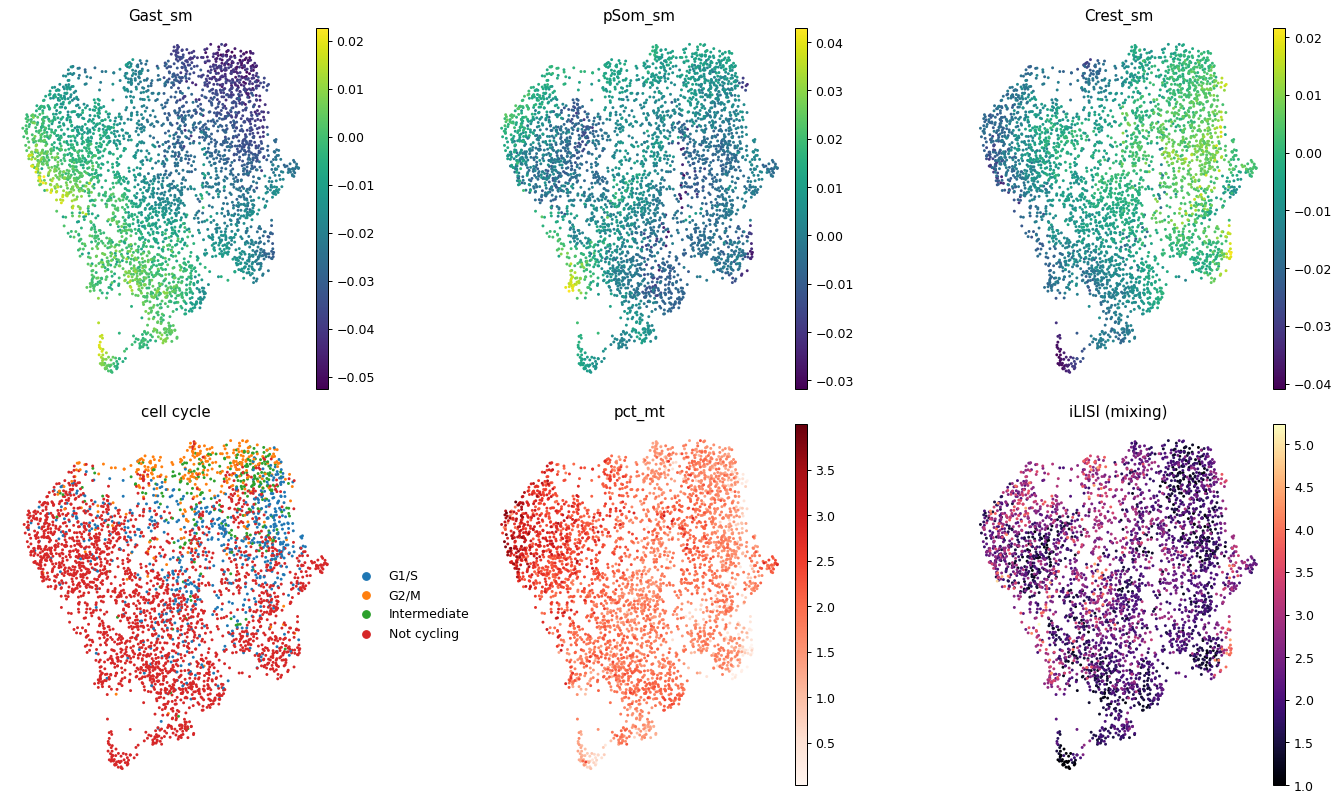

In [10]:
# visualise the sub-region biology on the regenerated embedding
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for j, nm in enumerate(['Gast_sm', 'pSom_sm', 'Crest_sm']):
    sc.pl.umap(adata, color=nm, size=22, cmap='viridis', frameon=False, show=False, ax=axes[0, j], title=nm)
sc.pl.umap(adata, color='cell_cycle_phase', size=22, frameon=False, show=False, ax=axes[1, 0], title='cell cycle')
sc.pl.umap(adata, color='pct_mt', size=22, cmap='Reds', frameon=False, show=False, ax=axes[1, 1], title='pct_mt')
sc.pl.umap(adata, color='iLISI', size=22, cmap='magma', frameon=False, show=False, ax=axes[1, 2], title='iLISI (mixing)')
fig.tight_layout()

### Subtype annotation — data markers + study meta-programs
Leiden (res=0.5) resolves seven transcriptional groups. Each is labelled from its
data-derived marker genes (`rank_genes_groups`) cross-checked against the dominant
Chen 2020 / 3CA malignant meta-program (`mp_top`) — using **both** the data and the
publication, as required. The programs are the NPC-appropriate, portable analogue of
Puram's HNSCC-specific Basal/Classical panel.

In [11]:
sc.tl.leiden(adata, resolution=0.5, random_state=SEED, flavor='igraph',
             n_iterations=2, directed=False)
adl = adata.copy()
sc.tl.rank_genes_groups(adl, 'leiden', method='wilcoxon', n_genes=12)

# Label each cluster from the CONTENT of its markers (robust to stochastic
# renumbering) and cross-check against the study's dominant meta-program (mp_top).
G2M = {'TOP2A','MKI67','UBE2C','CDK1','CENPF','CCNB1','CCNB2','BIRC5','NUSAP1','CDKN3'}
SPH = {'PCNA','TYMS','MCM6','MCM2','H2AFZ','HMGB2','RRM2','CLSPN','GINS2','TUBA1B','RAN'}
KRT = {'KRT5','KRT14','KRT6A','KRT17','SFN','S100A2','S100A11','A2ML1','KRT80','EMP1'}
def label_cluster(mk):
    top = mk[:12]
    n_mt = sum(g.startswith('MT-') for g in top)
    n_rp = sum(g.startswith(('RPL','RPS')) for g in top)
    if n_mt >= 4:                       return 'Metabolic (mito)'
    if n_rp >= 5:                       return 'Ribosomal'
    if len(set(top) & G2M) >= 2:        return 'Cell Cycle (G2/M)'
    if len(set(top) & SPH) >= 2:        return 'Proliferative (S)'
    if len(set(top) & KRT) >= 2:        return 'Epithelial'
    return None
print('cluster | top markers | marker-label | dominant mp_top')
subtype = {}
for cl in sorted(adata.obs.leiden.unique(), key=int):
    mk = list(adl.uns['rank_genes_groups']['names'][cl][:12])
    mp = adata.obs.loc[adata.obs.leiden == cl, 'mp_top'].value_counts()
    mp_dom = mp.index[0] if len(mp) else 'NA'
    lab = label_cluster(mk) or str(mp_dom)   # fall back to the study meta-program
    subtype[cl] = lab
    print(f'  c{cl} (n={(adata.obs.leiden==cl).sum():4d}): {mk[:8]} | {lab} | {mp_dom}')
adata.obs['subtype'] = adata.obs.leiden.map(subtype).astype('category')
print('subtypes:', adata.obs['subtype'].value_counts().to_dict())

cluster | top markers | marker-label | dominant mp_top
  c0 (n= 638): ['S100A11', 'S100A2', 'SFN', 'KRT5', 'S100A6', 'ANXA2', 'FXYD3', 'CSTB'] | Epithelial | Interferon/MHC-II (I)
  c1 (n= 333): ['RPL17', 'RPL35A', 'RPL32', 'RPL31', 'RPL15', 'RPS27A', 'RPS27', 'RPL13A'] | Ribosomal | Translation initiation
  c2 (n= 848): ['H2AFZ', 'YBX1', 'TUBA1B', 'CHCHD2', 'RAN', 'PTMA', 'SNRPD1', 'HMGB2'] | Proliferative (S) | Cell Cycle - G2/M
  c3 (n= 876): ['MT-ND4', 'MT-CO2', 'MT-ND2', 'MT-ND3', 'MT-CO3', 'MT-ATP6', 'MT-CYB', 'MT-CO1'] | Metabolic (mito) | Interferon/MHC-II (I)
  c4 (n= 582): ['RPL10', 'RPL10A', 'RPL13A', 'RPS4X', 'RPL28', 'RPS9', 'RPS27', 'RPL31'] | Ribosomal | Hypoxia
  c5 (n= 303): ['HMGB2', 'TOP2A', 'UBE2C', 'TUBA1B', 'NUSAP1', 'MKI67', 'CENPF', 'CDK1'] | Cell Cycle (G2/M) | Cell Cycle - G2/M
  c6 (n=  55): ['LMO7', 'EMP1', 'C15orf48', 'PRSS27', 'NDRG2', 'KRT80', 'ATP6V0E1', 'A2ML1'] | Epithelial | EpiSen
subtypes: {'Ribosomal': 915, 'Metabolic (mito)': 876, 'Proliferative (

### Gate 1 decision — mixed & continuous
**GO.** *Mixed:* the theta sweep lifts iLISI from ≈1.0 (patient-private islands) to a
≈2.1–2.2 plateau; at theta=5 all Leiden groups span 5–8 of the 8 patients — no
per-patient archipelago. *Continuous:* a single connected component; the three
embryonic signatures vary as smooth gradients (Gast/pSom-high origin → Crest-high
terminus), not block-wise by cluster. Sub-region biology is settled (cycling does not
confound Gast; low mito throughout), so no scoping is needed. Judged on the embedding
+ biology, not a scalar.

GATE 1 = GO  | 3635 cells, 8 samples | mean iLISI 2.16 | 1 connected component


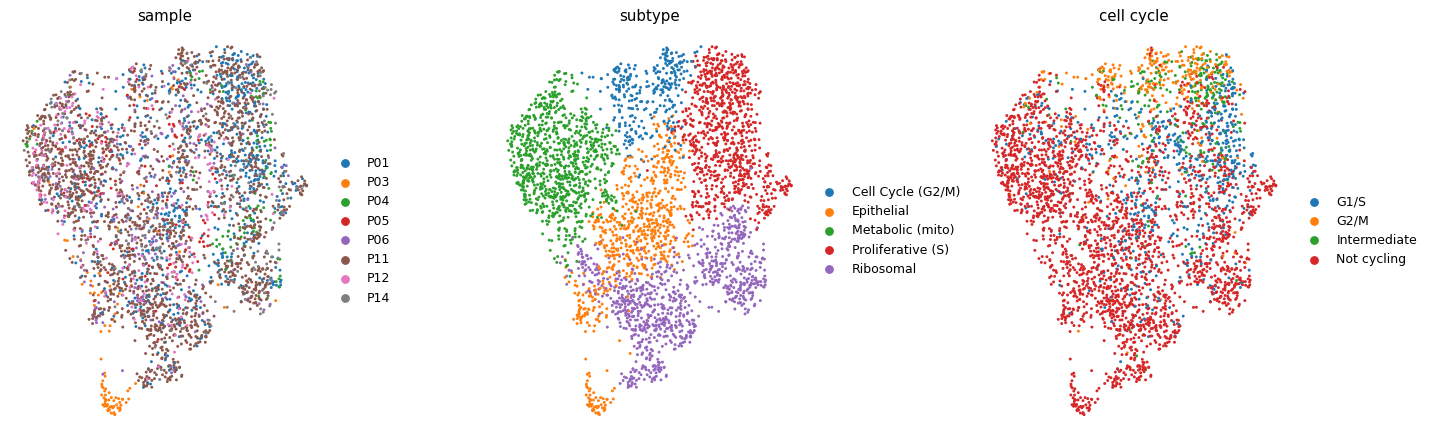

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
sc.pl.umap(adata, color='sample', size=22, frameon=False, show=False, ax=axes[0], title='sample')
sc.pl.umap(adata, color='subtype', size=22, frameon=False, show=False, ax=axes[1], title='subtype')
sc.pl.umap(adata, color='cell_cycle_phase', size=22, frameon=False, show=False, ax=axes[2], title='cell cycle')
fig.tight_layout()
print('GATE 1 = GO  | %d cells, %d samples | mean iLISI %.2f | 1 connected component'
      % (adata.n_obs, adata.obs['sample'].nunique(), adata.obs['iLISI'].mean()))

### Save processed data

In [13]:
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (3635, 22080)


### Sample-integration figure (deliverable)
Reference (Puram) layout: a single square UMAP of the whole malignant manifold,
coloured by `sample`. Intermixing of the eight patients across one continuous cloud
is the Gate-1 evidence. Raw embedding coordinates are kept (no axis inversion), so
this panel shares one orientation with `manifold.pdf` and the signature panels —
developmental origin on the left, Crest terminus on the right — rather than being
point-reflected relative to them.

saved samples.pdf


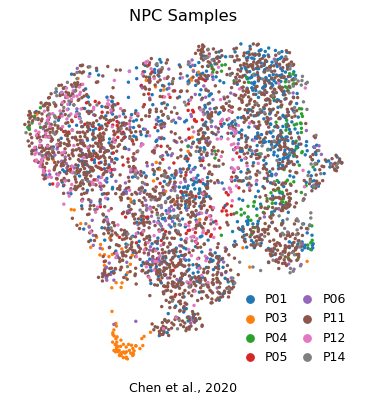

In [14]:
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
sc.pl.umap(adata, color='sample', size=30, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=2, frameon=False, loc='lower right',
          columnspacing=.5, handletextpad=.25)
ax.set_title('NPC Samples', size=13)
ax.text(.5, -.05, 'Chen et al., 2020', ha='center', transform=ax.transAxes)
fig.savefig(os.path.join(pth_fig, 'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf')